In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/superstore_cleaned.csv')

In [5]:
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
display(df.describe())

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.371723,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.705315,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
# Check dataset structure
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

In [8]:
# Check missing values in each column
print("\nMissing Values in Each Column:")
print(df.isnull().sum())



Missing Values in Each Column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [9]:

# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)


Total duplicate rows: 0


In [11]:
# Summary statistics
print("Sales Statistics:")
display(df['Sales'].describe())
print("\nProfit Statistics:")
display(df['Profit'].describe())


Sales Statistics:


,Sales
count,9994.000000
mean,229.858001
std,623.245101
min,0.444000
25%,17.280000
50%,54.490000
75%,209.940000
max,22638.480000



Profit Statistics:


,Profit
count,9994.000000
mean,28.656896
std,234.260108
min,-6599.978000
25%,1.728750
50%,8.666500
75%,29.364000
max,8399.976000


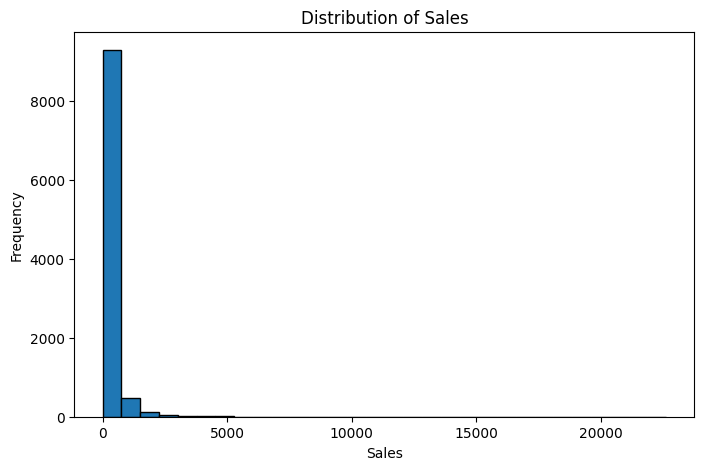

In [12]:
# Sales distribution
plt.figure(figsize=(8, 5))
plt.hist(df['Sales'], bins=30, edgecolor='black')
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()


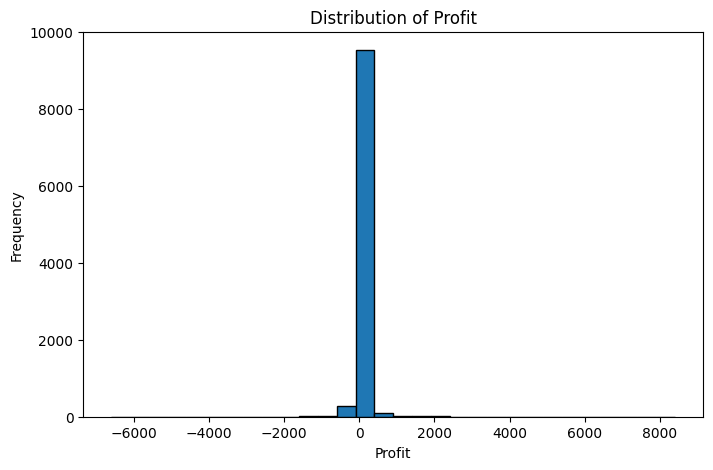

In [13]:
# Profit distribution
plt.figure(figsize=(8, 5))
plt.hist(df['Profit'], bins=30, edgecolor='black')
plt.title('Distribution of Profit')
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.show()

In [15]:
#Total Sales and Profit by category
category_analysis= df.groupby('Category')[['Sales','Profit']].sum()
print("Sales and Profit by Category:")
display(category_analysis)


Sales and Profit by Category:


,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


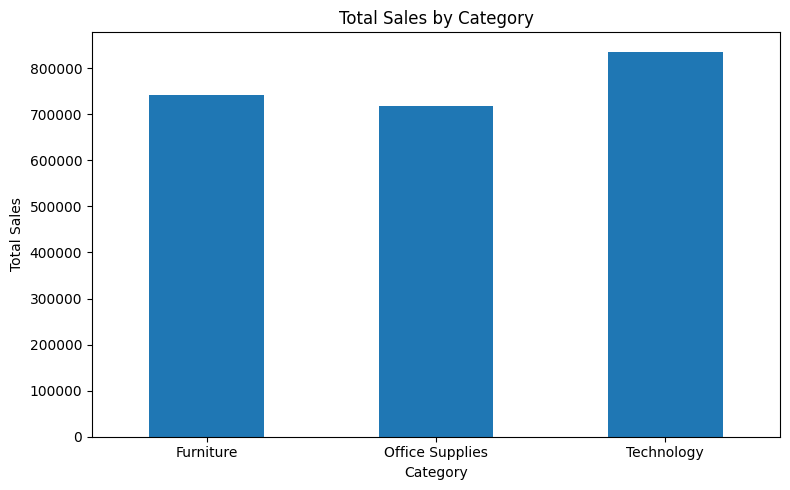

In [16]:
# Visualize sales by category
category_analysis['Sales'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Category',
    ylabel='Total Sales',
    xlabel='Category'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:

# Analyze sales and profit by region
region_analysis = df.groupby('Region')[['Sales', 'Profit']].sum()

print("Sales and Profit by Region:")
display(region_analysis)

Sales and Profit by Region:


,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


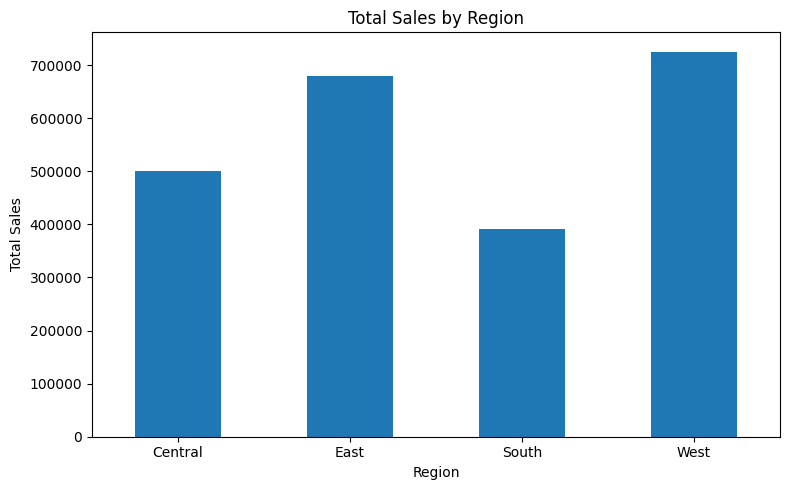

In [19]:
# Visualize sales by region
region_analysis['Sales'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Region',
    ylabel='Total Sales',
    xlabel='Region'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [37]:
# Convert Order Date to datetime
df['Order Date'] = pd.to_datetime(
    df['Order Date'], errors='coerce'
)

In [38]:

df_monthly = df.dropna(subset=['Order Date']).copy()

In [39]:
# Calculate monthly sales
df_monthly['Year-Month'] = (
    df_monthly['Order Date'].dt.to_period('M').astype(str)
)

monthly_sales = df_monthly.groupby('Year-Month')['Sales'].sum()

# Display monthly sales
display(monthly_sales.head(10))


,Sales
Year-Month,
2015-01,19640.427
2015-02,11833.618
2015-03,7159.670
2015-04,12455.482
2015-05,15280.411
2015-06,11927.849
2015-07,10222.428
2015-08,26797.763
2015-09,17158.932


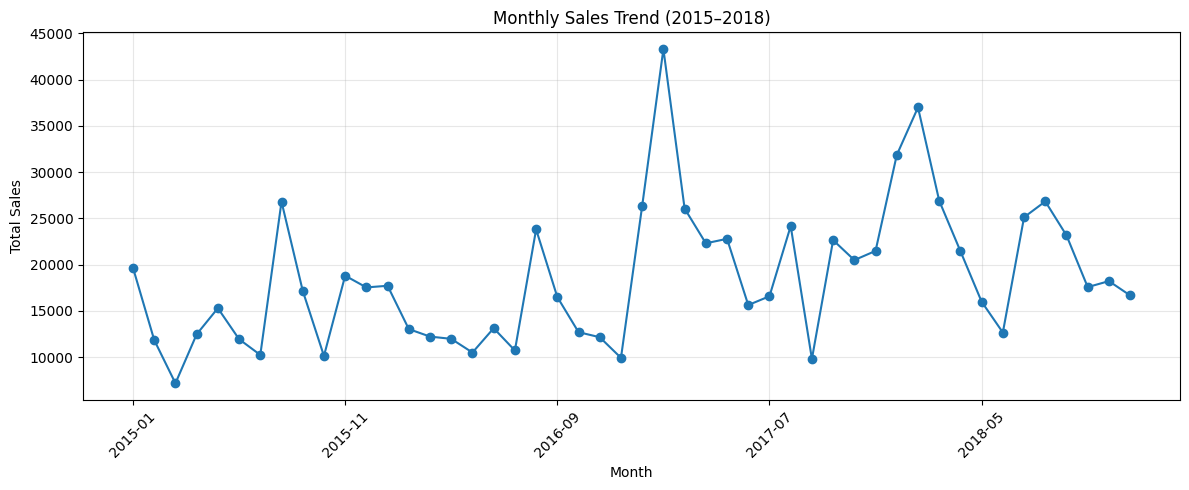

In [40]:

# Visualize monthly sales trend

plt.figure(figsize=(12, 5))

monthly_sales.sort_index().plot(
    kind='line',
    marker='o',
    linewidth=1.5
)

plt.title('Monthly Sales Trend (2015–2018)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [41]:

# Outlier Detection using the IQR Method

numeric_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Number of outliers:", len(outliers))
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))



Column: Sales
Number of outliers: 1167
Lower bound: -271.71
Upper bound: 498.93

Column: Quantity
Number of outliers: 170
Lower bound: -2.5
Upper bound: 9.5

Column: Discount
Number of outliers: 856
Lower bound: -0.3
Upper bound: 0.5

Column: Profit
Number of outliers: 1881
Lower bound: -39.72
Upper bound: 70.82


In [42]:
# Correlation analysis of numerical variables

numeric_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

correlation_matrix = df[numeric_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


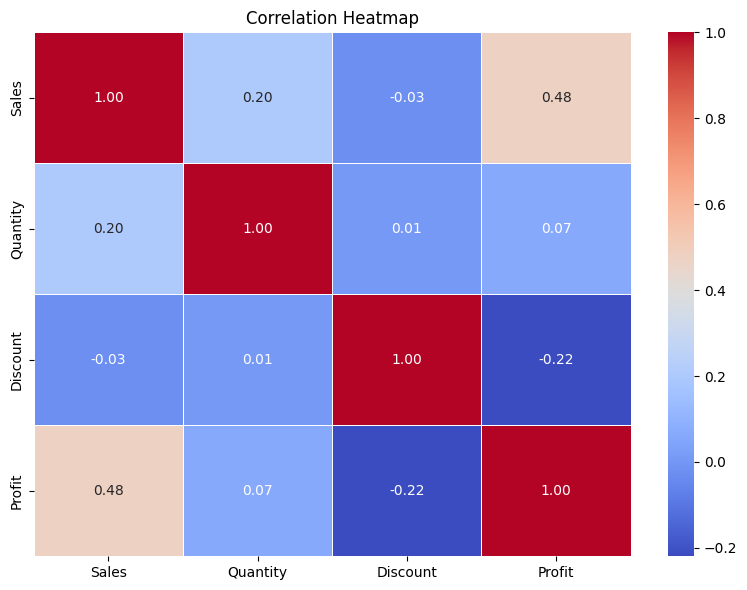

In [43]:
# Visualize correlations using a heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


### Correlation Analysis – Conclusion

The correlation analysis examined the relationships between Sales, Quantity, Discount, and Profit. Sales and Profit showed a moderate positive correlation of approximately 0.48. Discount and Profit showed a weak negative correlation of approximately -0.22, suggesting that higher discounts tend to be associated with lower profits. Sales and Quantity had a weak positive correlation of approximately 0.20. These findings describe linear associations and do not establish causation.


#  Key Business Insights and Recommendations

In [45]:

# Generate key business metrics

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
average_discount = df['Discount'].mean()
total_orders = df['Order ID'].nunique()

print("KEY BUSINESS METRICS")
print("-" * 35)
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Average Discount: {average_discount:.2%}")
print(f"Unique Orders: {total_orders:,}")

print("\nSALES BY REGION")
display(
    df.groupby('Region')['Sales']
      .sum()
      .sort_values(ascending=False)
)

print("\nPROFIT BY CATEGORY")
display(
    df.groupby('Category')['Profit']
      .sum()
      .sort_values(ascending=False)
)


KEY BUSINESS METRICS
-----------------------------------
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Average Discount: 15.62%
Unique Orders: 5,009

SALES BY REGION


,Sales
Region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050



PROFIT BY CATEGORY


,Profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728



## Key Business Insights and Recommendations

### Key Findings

1. **Overall Performance:** The dataset records total sales of **$2,297,200.86** and total profit of **$286,397.02** across **5,009 unique orders**.

2. **Regional Performance:** The West region generates the highest sales, followed by the East and Central regions. The South region has the lowest sales.

3. **Category Performance:** Technology is the most profitable category, followed by Office Supplies. Furniture generates considerably less profit than the other categories.

4. **Discount Impact:** The average discount is **15.62%**. The correlation analysis indicates a weak negative relationship between discount and profit, with a correlation coefficient of approximately **-0.22**.

5. **Monthly Sales Trend:** Monthly sales fluctuate throughout the analyzed period, with some months recording higher sales than others.

### Recommendations

- **Improve Regional Performance:** Investigate successful sales strategies in the West region and evaluate whether they can be applied to lower-performing regions.
- **Optimize Furniture Profitability:** Analyze Furniture products, costs, discounts, and pricing to identify opportunities to improve profit margins.
- **Review Discount Policies:** Evaluate the impact of discounts on profitability and consider appropriate discount strategies.
- **Monitor Sales Trends:** Track monthly sales and category-level performance to support business planning.
- **Use Data-Driven Decisions:** Regularly analyze sales, profits, and regional performance to identify opportunities for improvement.

### Conclusion

This project involved cleaning and analyzing the Sample Superstore dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis included data quality checks, sales and profit analysis, category and regional comparisons, monthly sales trends, outlier detection, and correlation analysis.

The results highlight regional sales differences, category-level profitability, and relationships between discounts and profit. These insights can help identify areas for further investigation and support data-driven business decisions.
